In [25]:
%matplotlib inline
import glob
import os
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

folder = r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\csv 1'

files = glob.glob(os.path.join(folder, '*.csv'))
print("找到的文件：")
for f in files:
    print("  ", os.path.basename(f))

dfs = []
for f in files:
    temp = pd.read_csv(f, encoding='latin1')
    dfs.append(temp)
    print(f"读入 {os.path.basename(f)}，形状 {temp.shape}")

df = pd.concat(dfs, ignore_index=True)

print(df.dtypes)#如果有好几个object，那就用df['列名'] = pd.to_numeric(df['列名'], errors='coerce')。。errors='coerce' 的意思是：能转成数字的就转，转不了的就变成 NaN（缺失值）。然后再 df.isnull().sum() 看看多出了多少 NaN，决定是删行还是填充

print("每列缺失值数量：")
print(df.isnull().sum())

print("数据形状：", df.shape)

df = df.sort_values('Time (h)').reset_index(drop=True)#各行编号就是 index；reset_index可以删去旧有index的映射；sort_values('Time (h)')表示用时间重排序，这样的话，就可以让index和时间顺序一一对应。
print("\n排序后前 5 行：")
print(df[['Time (h)', 'Utot (V)', 'ToutH2 (°C)', 'HrAIRFC (%)']].tail())

time_diff = df['Time (h)'].diff()
print("\n时间间隔统计：")
print(time_diff.describe())

print("\n电压统计：")
print(df['Utot (V)'].describe())

找到的文件：
   FC1_Ageing_part1.csv
   FC1_Ageing_part2.csv
   FC1_Ageing_part3.csv
读入 FC1_Ageing_part1.csv，形状 (65535, 25)
读入 FC1_Ageing_part2.csv，形状 (65535, 25)
读入 FC1_Ageing_part3.csv，形状 (12792, 25)
Time (h)           float64
U1 (V)             float64
U2 (V)             float64
U3 (V)             float64
U4 (V)             float64
U5 (V)             float64
Utot (V)           float64
J (A/cm²)          float64
I (A)              float64
TinH2 (°C)         float64
ToutH2 (°C)        float64
TinAIR (°C)        float64
ToutAIR (°C)       float64
TinWAT (°C)        float64
ToutWAT (°C)       float64
PinAIR (mbara)     float64
PoutAIR (mbara)    float64
PoutH2 (mbara)     float64
PinH2 (mbara)      float64
DinH2 (l/mn)       float64
DoutH2 (l/mn)      float64
DinAIR (l/mn)      float64
DoutAIR (l/mn)     float64
DWAT (l/mn)        float64
HrAIRFC (%)        float64
dtype: object
每列缺失值数量：
Time (h)           0
U1 (V)             0
U2 (V)             0
U3 (V)             0
U4 (V)             0
U

In [26]:
# 看时间列有多少重复值
print("重复时间行数：", df['Time (h)'].duplicated().sum())

# 看具体哪些时间是重复的（前 10 个）
dup_times = df[df['Time (h)'].duplicated(keep=False)]
print("\n重复时间的前 10 行：")
print(dup_times[['Time (h)', 'Utot (V)']].head(10))

重复时间行数： 15

重复时间的前 10 行：
         Time (h)  Utot (V)
12045   48.443766     3.343
12046   48.443766     3.362
22614  137.106707     3.313
22615  137.106707     3.315
28349  185.213554     3.309
28350  185.213554     3.308
39327  277.307893     3.296
39328  277.307893     3.296
47796  348.352354     3.277
47797  348.352354     3.298


In [4]:
df = df.drop_duplicates(subset='Time (h)', keep='first').reset_index(drop=True)
print("去重后数据形状：", df.shape)

去重后数据形状： (143847, 25)


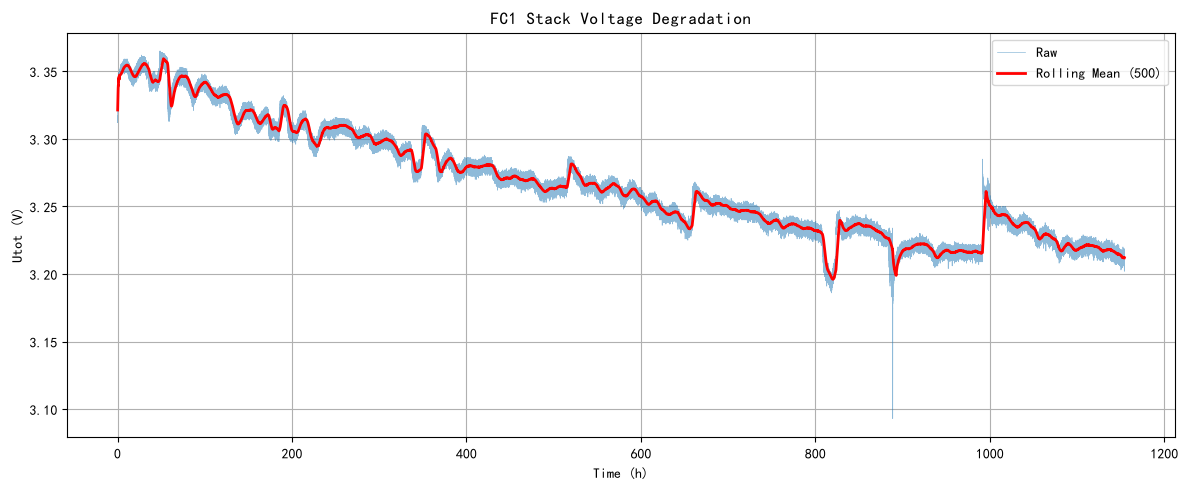

In [24]:
plt.figure(figsize=(12, 5))

# 原始电压（细线，半透明）
plt.plot(df['Time (h)'], df['Utot (V)'], linewidth=0.5, alpha=0.5, label='Raw')

# 滚动平均（粗线，窗口 500 个点，约 4 小时）
df['Utot_rolling'] = df['Utot (V)'].rolling(window=500).mean()
plt.plot(df['Time (h)'], df['Utot_rolling'], linewidth=2, color='red', label='Rolling Mean (500)')

plt.xlabel('Time (h)')
plt.ylabel('Utot (V)')
plt.title('FC1 Stack Voltage Degradation')
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.savefig(r'C:\Users\YOGA\Desktop\FC1_voltage.png', dpi=300, bbox_inches='tight')
plt.show()

In [6]:
time_diff = df['Time (h)'].diff()
print("\n时间间隔统计：")
print(time_diff.describe())

print("\n电压统计：")
print(df['Utot (V)'].describe())


时间间隔统计：
count    143846.000000
mean          0.008024
std           0.001677
min           0.000148
25%           0.008389
50%           0.008390
75%           0.008390
max           0.009182
Name: Time (h), dtype: float64

电压统计：
count    143847.000000
mean          3.270040
std           0.042673
min           3.093000
25%           3.234000
50%           3.263000
75%           3.305000
max           3.365000
Name: Utot (V), dtype: float64


In [7]:
# 1. 初始电压（前 100 个点的平均，避免单个噪声点影响）
V_initial = df['Utot (V)'].iloc[:100].mean()
print("初始电压 V_initial =", V_initial)

# 2. 最终电压（最后 100 个点的平均）
V_final = df['Utot (V)'].iloc[-100:].mean()
print("最终电压 V_final =", V_final)

# 3. 总衰减幅度
V_drop = V_initial - V_final
print("总衰减 =", V_drop, "V")
print("衰减百分比 =", V_drop / V_initial * 100, "%")

# 4. 找电压首次降到初始值 99% 的时间
threshold = V_initial * 0.99
print("\n99% 阈值 =", threshold, "V")

# 用滚动平均找，避免噪声误触发
df['Utot_rolling'] = df['Utot (V)'].rolling(window=500).mean()

below = df[df['Utot_rolling'] < threshold]
if len(below) > 0:
    t_99 = below['Time (h)'].iloc[0]
    print("首次低于 99% 的时间：", t_99, "h")
else:
    print("整段数据中电压从未降到 99% 以下")
    print("最低滚动平均 =", df['Utot_rolling'].min())

初始电压 V_initial = 3.31699
最终电压 V_final = 3.21273
总衰减 = 0.10426000000000002 V
衰减百分比 = 3.1432111643387537 %

99% 阈值 = 3.2838201000000002 V
首次低于 99% 的时间： 339.5598894 h


In [8]:
# 1. 初始电压（前 100 个点的平均，避免单个噪声点影响）
V_initial = df['Utot (V)'].iloc[:100].mean()
print("初始电压 V_initial =", V_initial)

# 2. 最终电压（最后 100 个点的平均）
V_final = df['Utot (V)'].iloc[-100:].mean()
print("最终电压 V_final =", V_final)

# 3. 总衰减幅度
V_drop = V_initial - V_final
print("总衰减 =", V_drop, "V")
print("衰减百分比 =", V_drop / V_initial * 100, "%")

# 4. 找电压首次降到初始值 99.5% 的时间
threshold = V_initial * 0.995
print("\n995% 阈值 =", threshold, "V")

# 用滚动平均找，避免噪声误触发
df['Utot_rolling'] = df['Utot (V)'].rolling(window=500).mean()

below = df[df['Utot_rolling'] < threshold]
if len(below) > 0:
    t_995 = below['Time (h)'].iloc[0]
    print("首次低于 99% 的时间：", t_995, "h")
else:
    print("整段数据中电压从未降到 99% 以下")
    print("最低滚动平均 =", df['Utot_rolling'].min())

初始电压 V_initial = 3.31699
最终电压 V_final = 3.21273
总衰减 = 0.10426000000000002 V
衰减百分比 = 3.1432111643387537 %

995% 阈值 = 3.30040505 V
首次低于 99% 的时间： 222.5144311 h


In [9]:
# 1. 初始电压（前 100 个点的平均，避免单个噪声点影响）
V_initial = df['Utot (V)'].iloc[:100].mean()
print("初始电压 V_initial =", V_initial)

# 2. 最终电压（最后 100 个点的平均）
V_final = df['Utot (V)'].iloc[-100:].mean()
print("最终电压 V_final =", V_final)

# 3. 总衰减幅度
V_drop = V_initial - V_final
print("总衰减 =", V_drop, "V")
print("衰减百分比 =", V_drop / V_initial * 100, "%")

# 4. 找电压首次降到初始值 99.5% 的时间
threshold = V_initial * 0.998
print("\n998% 阈值 =", threshold, "V")

# 用滚动平均找，避免噪声误触发
df['Utot_rolling'] = df['Utot (V)'].rolling(window=500).mean()

below = df[df['Utot_rolling'] < threshold]
if len(below) > 0:
    t_998 = below['Time (h)'].iloc[0]
    print("首次低于 99% 的时间：", t_998, "h")
else:
    print("整段数据中电压从未降到 99% 以下")
    print("最低滚动平均 =", df['Utot_rolling'].min())

初始电压 V_initial = 3.31699
最终电压 V_final = 3.21273
总衰减 = 0.10426000000000002 V
衰减百分比 = 3.1432111643387537 %

998% 阈值 = 3.31035602 V
首次低于 99% 的时间： 176.0016028 h


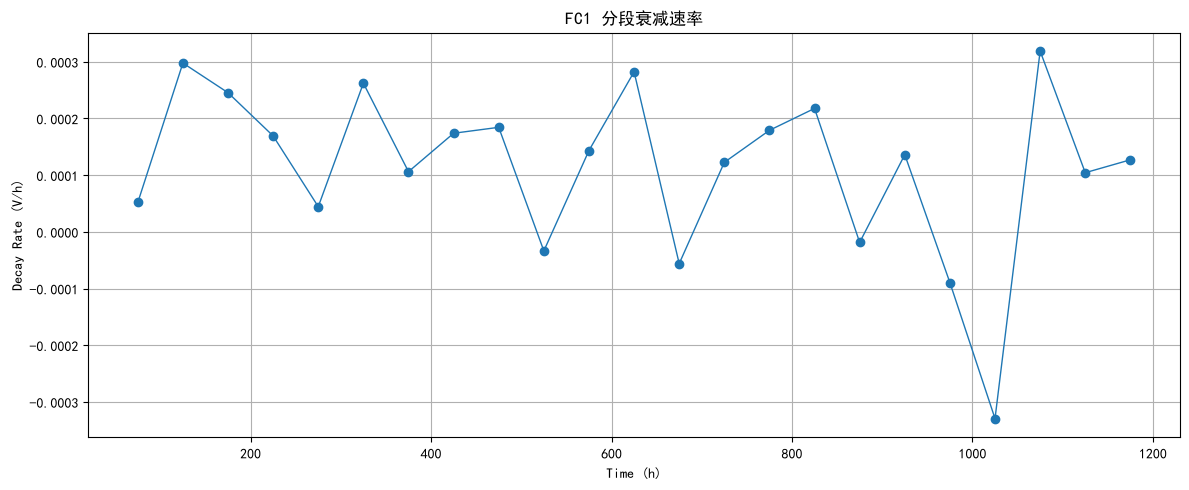

时间段中点 (h) | 衰减速率 (V/h)
    75.0      | 0.000052
   125.0      | 0.000298
   175.0      | 0.000245
   225.0      | 0.000169
   275.0      | 0.000044
   325.0      | 0.000262
   375.0      | 0.000106
   425.0      | 0.000174
   475.0      | 0.000184
   525.0      | -0.000034
   575.0      | 0.000143
   625.0      | 0.000282
   675.0      | -0.000056
   725.0      | 0.000123
   775.0      | 0.000179
   825.0      | 0.000218
   875.0      | -0.000019
   925.0      | 0.000136
   975.0      | -0.000089
  1025.0      | -0.000329
  1075.0      | 0.000319
  1125.0      | 0.000104
  1175.0      | 0.000127


In [16]:
    # 分段算衰减速率：每 50 小时一段
import numpy as np

# 生成分段边界
t_start = df['Time (h)'].min()
t_end = df['Time (h)'].max()
bin_edges = np.arange(t_start, t_end + 50, 50)   # 每 50 小时一个边界

# 每段的平均电压
bin_centers = []
bin_voltages = []

for i in range(len(bin_edges) - 1):
    left = bin_edges[i]
    right = bin_edges[i + 1]
    segment = df[(df['Time (h)'] >= left) & (df['Time (h)'] < right)]
    if len(segment) > 0:
        bin_centers.append((left + right) / 2)
        bin_voltages.append(segment['Utot (V)'].mean())

# 算相邻两段的电压差，除以时间差，得到衰减速率
bin_centers = np.array(bin_centers)
bin_voltages = np.array(bin_voltages)

decay_rate = -np.diff(bin_voltages) / 50   # 加负号，让正值表示“衰减速率”

# 画图
plt.figure(figsize=(12, 5))
plt.plot(bin_centers[1:], decay_rate, marker='o', linewidth=1)
plt.xlabel('Time (h)')
plt.ylabel('Decay Rate (V/h)')
plt.title('FC1 分段衰减速率')
plt.grid(True)
plt.tight_layout()
plt.savefig(r'C:\Users\YOGA\Desktop\FC1_voltage rate1.png', dpi=300, bbox_inches='tight')
plt.show()

# 打印数值
print("时间段中点 (h) | 衰减速率 (V/h)")
for t, r in zip(bin_centers[1:], decay_rate):
    print(f"{t:8.1f}      | {r:.6f}")

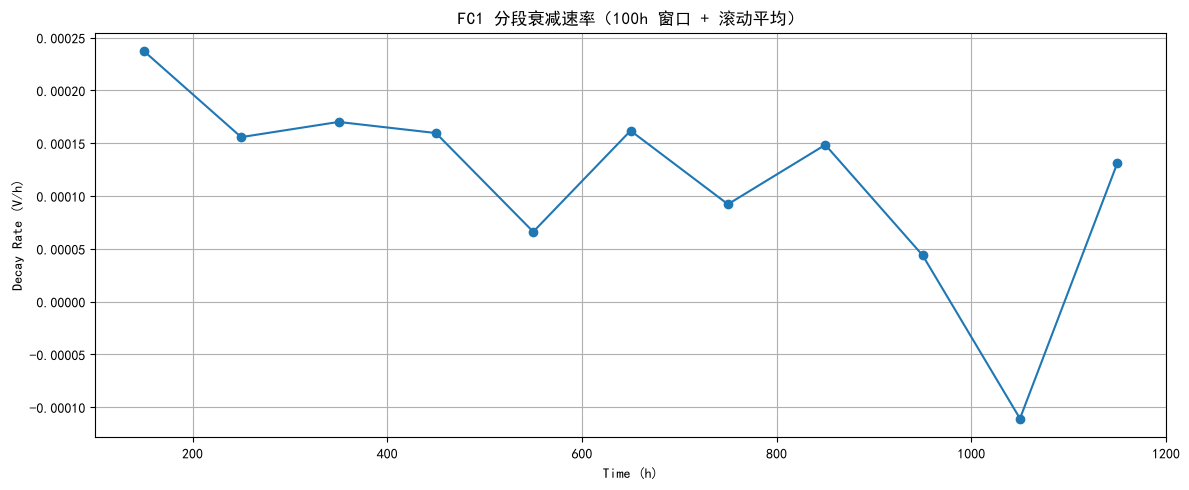

时间段中点 (h) | 衰减速率 (V/h)
   150.0      | 0.000237
   250.0      | 0.000156
   350.0      | 0.000170
   450.0      | 0.000160
   550.0      | 0.000066
   650.0      | 0.000162
   750.0      | 0.000092
   850.0      | 0.000148
   950.0      | 0.000044
  1050.0      | -0.000111
  1150.0      | 0.000131


In [18]:
import numpy as np

# 先算滚动平均（窗口 2000 个点，约 17 小时）
df['Utot_smooth'] = df['Utot (V)'].rolling(window=2000, center=True).mean()

# 用 100 小时分段
t_start = df['Time (h)'].min()
t_end = df['Time (h)'].max()
bin_edges = np.arange(t_start, t_end + 100, 100)

bin_centers = []
bin_voltages = []

for i in range(len(bin_edges) - 1):
    left = bin_edges[i]
    right = bin_edges[i + 1]
    segment = df[(df['Time (h)'] >= left) & (df['Time (h)'] < right)]
    if len(segment) > 0:
        bin_centers.append((left + right) / 2)
        bin_voltages.append(segment['Utot_smooth'].mean())

bin_centers = np.array(bin_centers)
bin_voltages = np.array(bin_voltages)

decay_rate = -np.diff(bin_voltages) / 100

plt.figure(figsize=(12, 5))
plt.plot(bin_centers[1:], decay_rate, marker='o', linewidth=1.5)
plt.xlabel('Time (h)')
plt.ylabel('Decay Rate (V/h)')
plt.title('FC1 分段衰减速率（100h 窗口 + 滚动平均）')
plt.grid(True)
plt.tight_layout()
plt.savefig(r'C:\Users\YOGA\Desktop\FC1_voltage rate2.png', dpi=300, bbox_inches='tight')
plt.show()

print("时间段中点 (h) | 衰减速率 (V/h)")
for t, r in zip(bin_centers[1:], decay_rate):
    print(f"{t:8.1f}      | {r:.6f}")

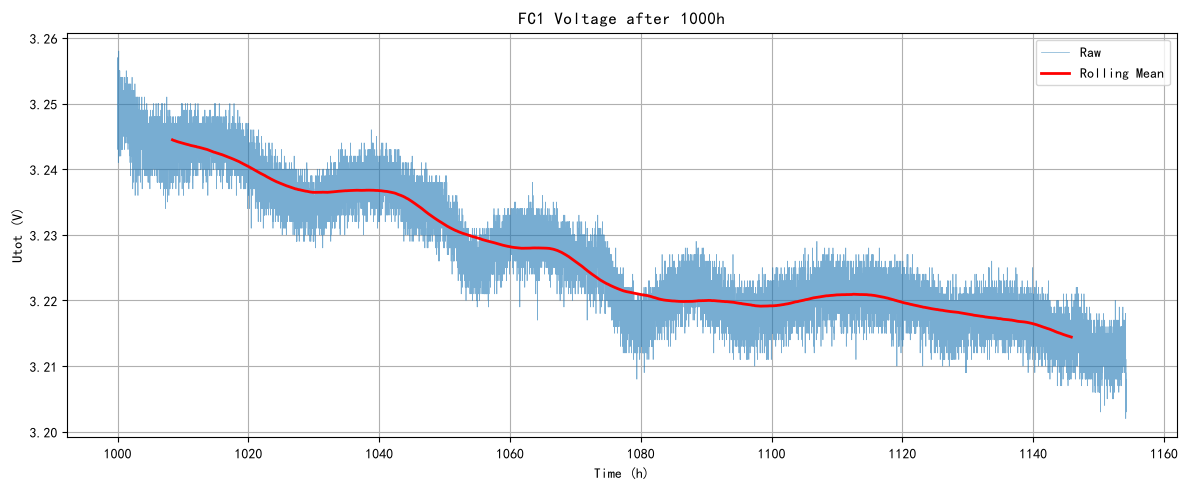

1000h 后数据点数： 18382
1000h 后电压范围： 3.202 到 3.258


In [21]:
# 只看 1000 小时之后的数据
tail = df[df['Time (h)'] > 1000]

plt.figure(figsize=(12, 5))
plt.plot(tail['Time (h)'], tail['Utot (V)'], linewidth=0.5, alpha=0.6, label='Raw')
tail_smooth = tail['Utot (V)'].rolling(window=2000, center=True).mean()
plt.plot(tail['Time (h)'], tail_smooth, linewidth=2, color='red', label='Rolling Mean')
plt.xlabel('Time (h)')
plt.ylabel('Utot (V)')
plt.title('FC1 Voltage after 1000h')
plt.legend()
plt.grid(True)
plt.tight_layout()

df.to_csv(r'C:\Users\YOGA\Desktop\电池ai分析\IEEE2014DataChallengeData\IEEE 2014 Data Challenge Data\FC1_Without_Ripples\FC1_full.csv', index=False, encoding='utf-8-sig')
# 保存到桌面，格式 png，分辨率 300 dpi
#plt.savefig(r'C:\Users\YOGA\Desktop\FC1_voltage.png', dpi=300, bbox_inches='tight')
plt.savefig(r'C:\Users\YOGA\Desktop\FC1_voltage ending.png', dpi=300, bbox_inches='tight')

plt.show()

print("1000h 后数据点数：", len(tail))
print("1000h 后电压范围：", tail['Utot (V)'].min(), "到", tail['Utot (V)'].max())

In [13]:
plt.savefig(r'C:\Users\YOGA\Desktop\FC1_voltage.png', dpi=300, bbox_inches='tight')

<Figure size 640x480 with 0 Axes>

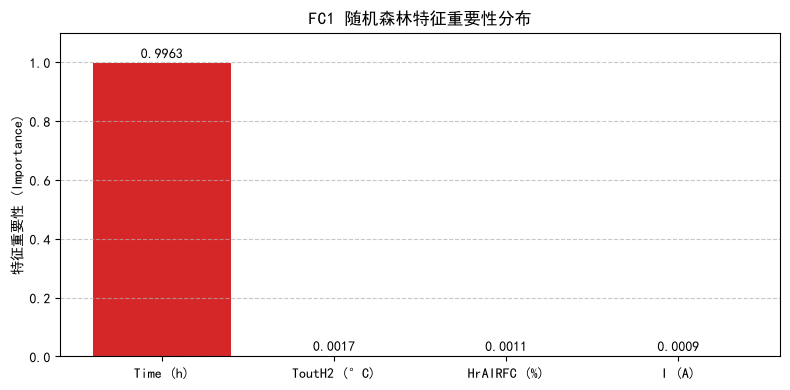

In [1]:
import matplotlib.pyplot as plt
import numpy as np

plt.rcParams['font.sans-serif'] = ['SimHei']
plt.rcParams['axes.unicode_minus'] = False

# 你的特征重要性数据
features = ['Time (h)', 'ToutH2 (°C)', 'HrAIRFC (%)', 'I (A)']
importances = [0.9963, 0.0017, 0.0011, 0.0009]  # 电流那个补个大概值，或者用你跑出来的真实值

plt.figure(figsize=(8, 4))
bars = plt.bar(features, importances, color=['#d62728', '#1f77b4', '#2ca02c', '#ff7f0e'])

# 在柱子上标数字
for bar in bars:
    yval = bar.get_height()
    plt.text(bar.get_x() + bar.get_width()/2, yval + 0.01, f'{yval:.4f}', ha='center', va='bottom')

plt.ylim(0, 1.1)
plt.ylabel('特征重要性 (Importance)')
plt.title('FC1 随机森林特征重要性分布')
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()

# 保存
plt.savefig(r'C:\Users\YOGA\Desktop\FC1_feature_importance.png', dpi=300, bbox_inches='tight')
plt.show()